# Step 1 - Qualitity controls (QC) & cell filtering (Nestorowa et al.)

This notebook computes the QCs of the raw data provided based on the criterias listed in **Nestorowa et al. (2016)** (GSE81682).
It also contains an analysis part that aims to compare our QcC results with those obtaine in **Chevalier et al.**.

To use the notebook, please use the data_treetment_env from the corresponding yml file.
The cells should be run top to bottom, and the results and QC filtered data will be found in the Results/Data_treatment_outputs folder.

## 1. Load packages & data

In [ ]:
import numpy as np
import pandas as pd
import mygene
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
counts_path = "../Data/nestorowa_singlecell_raw_data_taken_from_original_paper_GSE.txt.gz"

# Reading TSV.GZ file with explicit compression
raw_df = pd.read_csv(counts_path, sep="\t", index_col=0, compression="gzip")
raw_counts = raw_df.astype(float)

# Check if data is clean
assert not raw_counts.index.duplicated().any(), "Gene duplicates"
assert not raw_counts.isna().any().any(), "NA values detected"
assert (raw_counts.values >= 0).all(), "Negative counts detected"

print(f"Raw rows (genes)    : {raw_counts.shape[0]}")
print(f"Raw columns (cells) : {raw_counts.shape[1]}")

Raw rows (genes)    : 46175
Raw columns (cells) : 1920


## 2. Identifying gene types

### 2.1 Sort gene types by their format

The raw GEO table contains more than genes. Rows beginning `__` are HTSeq summary categories such as `__not_aligned`, not genes.

- `^ENSMUSG` identifies mouse Ensembl gene rows.
- `^ERCC[-_]` identifies ERCC spike-ins (genes used as measure indicators).
- `^__` identifies HTSeq summary rows.
- `is_unknown` is a safety check that stops the analysis if an unexpected row type appears.

This separation is necessary because HTSeq summary rows are useful for reconstructing QC totals but must never enter normalization or gene-variability analysis.

In [6]:
ids = raw_counts.index.to_series()

is_endogenous = ids.str.contains(r"^ENSMUSG", regex=True)
is_ercc = ids.str.contains(r"^ERCC[-_]", case=False, regex=True)
is_htseq = ids.str.contains(r"^__", regex=True)
is_unknown = ~(is_endogenous | is_ercc | is_htseq)

summary_df = pd.DataFrame({
    'Class': ["ENSMUSG (normal gene)", "ERCC", "HTSeq", "Unknown"],
    'Number_of_genes': [is_endogenous.sum(), is_ercc.sum(), is_htseq.sum(), is_unknown.sum()]
})
print(summary_df)

if is_unknown.any():
    raise ValueError(f"Unknown genes : {list(ids[is_unknown])}")

                   Class  Number_of_genes
0  ENSMUSG (normal gene)            46078
1                   ERCC               92
2                  HTSeq                5
3                Unknown                0


The mixed table is split into three matrices because each row type has a different role:

- `endogenous_counts` — biological mouse-gene expression;
- `ercc_counts` — external technical controls;
- `htseq_counts` — mapping/counting bookkeeping used only for QC reconstruction.

In [7]:
endogenous_counts = raw_counts.loc[is_endogenous]
ercc_counts = raw_counts.loc[is_ercc]
htseq_counts = raw_counts.loc[is_htseq]

### 2.2 Identifying mitochodrial RNA

Nestorowa does not provide R code or the exact mitochondrial-ID vector used in their analysis. The code therefore constructs the 37 GRCm38 mitochondrial Ensembl genes explicitly.

`is_mito_full` marks mitochondrial endogenous rows and `is_nuclear_full` defines the remaining endogenous genes as nuclear. Missing mitochondrial IDs are printed so the calculation can be audited.

In [8]:
grcm38_mito_ensembl = [f"ENSMUSG000000{i}" for i in range(64336, 64362)] + \
                      [f"ENSMUSG000000{i}" for i in range(64363, 64373)] + \
                      ["ENSMUSG00000065947"]

assert len(grcm38_mito_ensembl) == 37

is_mito_full = is_endogenous & ids.isin(grcm38_mito_ensembl)
is_nuclear_full = is_endogenous & ~is_mito_full

print(f"Expected mithocondrial genes : 37")
print(f"Mitochondrial genes present in the matrix : {is_mito_full.sum()}")

Expected mithocondrial genes : 37
Mitochondrial genes present in the matrix : 37


## 3. Compute the cell-filtering QC based on Nestorowa's criterias

### 3.1 Define the fours Nestorowa QC thershholds

**Source: Nestorowa et al. (2016).**

These values are defined here, immediately before the QC quantities are calculated:

- at least **200,000 reads mapping to nuclear genes**
- at least **4,000 detected genes**
- **<10%** of mapped reads mapping to mitochondrial genes
- **<50%** of mapped reads mapping to ERCC spike-ins.

In [9]:
# Quality control thresholds (Nestorowa et al. 2016)
MIN_NUCLEAR_READS = 200000
MIN_DETECTED_GENES = 4000
MAX_MITO_PCT = 10
MAX_ERCC_PCT = 50

# Comparaison variable
NESTOROWA_REPORTED_CELLS = 1656

### 3.2 Computing the metrics cell by cell

The function `get_htseq_row()` retrieves one HTSeq summary category across all cells.

The code then constructs:

- `raw_total_reads` — the sum of every HTSeq-reported row;
- `mapped_reads` — reconstructed as total records minus `__not_aligned`;
- `nuclear_reads` — reads assigned to nuclear Ensembl genes;
- `mitochondrial_reads` — reads assigned to the mitochondrial set;
- `ercc_reads` — reads assigned to ERCC controls;
- `assigned_feature_reads` — reads assigned to endogenous genes or ERCCs.

Finally:

- `mito_pct_mapped = 100 × mitochondrial_reads / mapped_reads`;
- `ercc_pct_mapped = 100 × ercc_reads / mapped_reads`.

The resulting `qc` data frame stores all cell-level QC quantities before filtering.

In [10]:
def get_htseq_row(row_name):
    if row_name in htseq_counts.index:
        return htseq_counts.loc[row_name].values
    return np.zeros(raw_counts.shape[1])

raw_total_reads = raw_counts.sum(axis=0)
not_aligned = get_htseq_row("__not_aligned")
mapped_reads = raw_total_reads - not_aligned

nuclear_reads = raw_counts.loc[is_nuclear_full].sum(axis=0)
mitochondrial_reads = raw_counts.loc[is_mito_full].sum(axis=0)
ercc_reads = ercc_counts.sum(axis=0)
assigned_feature_reads = endogenous_counts.sum(axis=0) + ercc_reads

# Number of non null genes (detected genes) for protein coding genes
detected_genes = (endogenous_counts > 0).sum(axis=0)

mito_pct_mapped = 100 * mitochondrial_reads / mapped_reads
ercc_pct_mapped = 100 * ercc_reads / mapped_reads

qc = pd.DataFrame({
    'cell': raw_counts.columns,
    'raw_total_reads': raw_total_reads,
    'mapped_reads': mapped_reads,
    'assigned_feature_reads': assigned_feature_reads,
    'nuclear_reads': nuclear_reads,
    'detected_genes': detected_genes,
    'mitochondrial_reads': mitochondrial_reads,
    'ercc_reads': ercc_reads,
    'mito_pct_mapped': mito_pct_mapped,
    'ercc_pct_mapped': ercc_pct_mapped
})

# Stastistical summary of QC metrics
qc[["mapped_reads", "nuclear_reads", "detected_genes", "mito_pct_mapped", "ercc_pct_mapped"]].describe()

,mapped_reads,nuclear_reads,detected_genes,mito_pct_mapped,ercc_pct_mapped
count,1.920000e+03,1.920000e+03,1920.000000,1920.000000,1920.000000
mean,2.370257e+06,1.492945e+06,11722.292187,3.412938,13.415637
std,2.529989e+06,1.840667e+06,1931.462240,1.500806,14.688989
min,2.049200e+04,1.117100e+04,4711.000000,0.026068,0.508449
25%,9.241348e+05,5.102075e+05,10444.500000,2.737429,5.225001
50%,1.740597e+06,1.031638e+06,11806.000000,3.442683,8.208479
75%,3.027296e+06,1.893653e+06,13100.250000,4.144500,14.394833
max,4.647587e+07,3.520097e+07,21606.000000,21.387042,91.860233


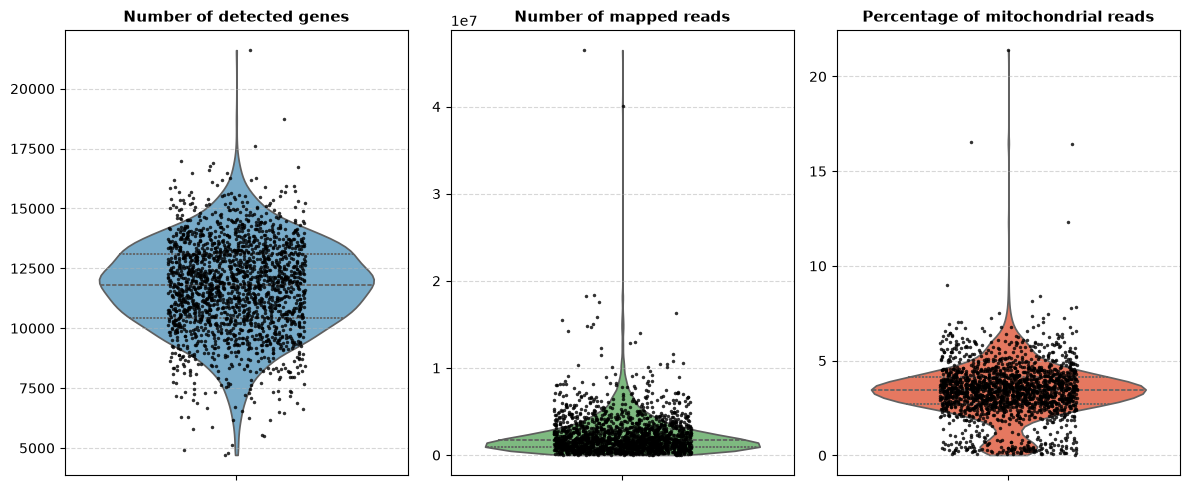

In [11]:
# Generating visual plots for QC metrics

metrics = ["detected_genes", "mapped_reads", "mito_pct_mapped"]
titles = [
    "Number of detected genes",
    "Number of mapped reads",
    "Percentage of mitochondrial reads",
]
colors = ["#6BAED6", "#74C476", "#FB6A4A"]

fig, axes = plt.subplots(1, len(metrics), figsize=(12, 5))

for i, metric in enumerate(metrics):
    if metric in qc.columns:
        # Density
        sns.violinplot(
            y=qc[metric],
            ax=axes[i],
            color=colors[i],
            inner="quartile", 
            cut=0, 
        )

        # Individual values
        sns.stripplot(
            y=qc[metric],
            ax=axes[i],
            color="black",
            alpha=0.8,  # Transparency to see the density
            jitter=0.2,  # Horizontal jitter to avoid overlap
            size=2.5,
        )

        axes[i].set_title(titles[i], fontsize=11, fontweight="bold")
        axes[i].set_ylabel("")
        axes[i].grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("../Results/Data_treatment_outputs/QC_metrics_violin_plots.png", dpi=300)
plt.show()

### 3.3 Apply the filters to the raw data

In [12]:
qc['pass_nuclear'] = qc['nuclear_reads'] >= MIN_NUCLEAR_READS
qc['pass_genes'] = qc['detected_genes'] >= MIN_DETECTED_GENES
qc['pass_mito'] = qc['mito_pct_mapped'] < MAX_MITO_PCT
qc['pass_ercc'] = qc['ercc_pct_mapped'] < MAX_ERCC_PCT

qc['pass_all'] = (
    qc['pass_nuclear'] &
    qc['pass_genes'] &
    qc['pass_mito'] &
    qc['pass_ercc']
)

print(f"Initial cells             : {len(qc)}")
print(f"Cells retained (QC)       : {qc['pass_all'].sum()}")
print(f"Reported in the article   : {NESTOROWA_REPORTED_CELLS}")
print(f"Difference                : {qc['pass_all'].sum() - NESTOROWA_REPORTED_CELLS}\n")

Initial cells             : 1920
Cells retained (QC)       : 1691
Reported in the article   : 1656
Difference                : 35



## 4. Extract the final matrix and save to tsv format

In [13]:
keep_cells = qc.loc[qc['pass_all'], 'cell']

endogenous_qc = endogenous_counts[keep_cells]
ercc_qc = ercc_counts[keep_cells]

# Get rid of genes that are not expressed in cells after QC filtering
endogenous_qc = endogenous_qc.loc[endogenous_qc.sum(axis=1) > 0]
ercc_qc = ercc_qc.loc[ercc_qc.sum(axis=1) > 0]

print(f"Cells            : {endogenous_qc.shape[1]}")
print(f"Endogenous genes : {endogenous_qc.shape[0]}")
print(f"ERCCs filtered   : {ercc_qc.shape[0]}")

Cells            : 1691
Endogenous genes : 43152
ERCCs filtered   : 92


In [14]:
endogenous_qc.to_csv("../Results/Data_treatment_outputs/cell_QC_filtered_data.tsv.gz", sep="\t", compression="gzip")
qc.to_csv("../Results/Data_treatment_outputs/cell_QC_metrics.tsv.gz", sep="\t", compression="gzip")

## Analysis of the results - comparaison with **Chevalier et al.**

This ensables to identify and compare the exclusion step of the cells between our QC analysis and Chevalier's QC filtered data.

In [15]:
def get_exclusion_reasons(qc_df):
    """
    Determine the reasons for exclusion based on QC criteria and adds a new column
    to the DataFrame indicating the reasons for exclusion.
    """
    reasons = []
    for _, row in qc_df.iterrows():
        if row['pass_all']:
            reasons.append("Retained (PASS)")
        else:
            failed_criteria = []
            if not row['pass_nuclear']:
                failed_criteria.append("Nuclear reads (< 200k)")
            if not row['pass_genes']:
                failed_criteria.append("Coding genes (< 4k)")
            if not row['pass_mito']:
                failed_criteria.append("Mitochondrial (>= 10%)")
            if not row['pass_ercc']:
                failed_criteria.append("ERCC (>= 50%)")
            reasons.append(" & ".join(failed_criteria))
            
    qc_df['exclusion_status'] = reasons
    return qc_df

# Application sur le DataFrame QC
qc = get_exclusion_reasons(qc)

print("--- Exclusion by criteria --- ")
print(qc['exclusion_status'].value_counts())

--- Exclusion by criteria --- 
exclusion_status
Retained (PASS)                                    1691
Nuclear reads (< 200k)                              141
Nuclear reads (< 200k) & ERCC (>= 50%)               84
Mitochondrial (>= 10%)                                2
Nuclear reads (< 200k) & Mitochondrial (>= 10%)       2
Name: count, dtype: int64


Here it is notable that all cell that have an ERCC percentage over 50% also come with a low number of nuclear reads. This might make the criteria obsolete.

In [16]:
def compare_and_diagnose_with_chevalier(qc_df, chevalier_filepath):
    try:
        chevalier_df = pd.read_csv(chevalier_filepath, sep="\t", index_col=0)
        chevalier_cells = set(chevalier_df.columns)
        
        qc_pass_cells = set(qc_df.loc[qc_df['pass_all'], 'cell'])
        all_raw_cells = set(qc_df['cell'])
        
        in_qc_not_chevalier = qc_pass_cells - chevalier_cells
        in_chevalier_not_qc = chevalier_cells - qc_pass_cells
        
        print("\n==================================================")
        print("1. Comparaison")
        print("==================================================")
        print(f"Cells validated in our QC            : {len(qc_pass_cells)}")
        print(f"Cells validated in Chevalier et al.  : {len(chevalier_cells)}")
        print(f"Common cells                         : {len(qc_pass_cells.intersection(chevalier_cells))}")
        print(f"Cells in our QC but NOT in Chevalier : {len(in_qc_not_chevalier)}")
        print(f"Cells in Chevalier but NOT in our QC : {len(in_chevalier_not_qc)}")
        
        print("\n==================================================")
        print("2. Details on cells present in Chevalier & excluded in our QC")
        print("==================================================")
        
        chevalier_exclues_df = qc_df[qc_df['cell'].isin(in_chevalier_not_qc)].copy()
        
        if not chevalier_exclues_df.empty:
            not_in_raw = in_chevalier_not_qc - all_raw_cells
            if not_in_raw:
                print(f" {len(not_in_raw)} Chevalier cells are not in the raw data.")
            
            print("\nExclusion reasons :")
            print(chevalier_exclues_df['exclusion_status'].value_counts())
            
            print("\nDDetail of metrics for the cells excluded from Chevalier :")
            cols_to_show = ['cell', 'nuclear_reads', 'detected_genes', 'mito_pct_mapped', 'ercc_pct_mapped', 'exclusion_status']
            print(chevalier_exclues_df[cols_to_show].to_string(index=False))
        else:
            print("All cells in Chevalier et al. were retained by our QC")
            
        print("\n==================================================")
        print("3. Cells retained by our QC but absent in Chevalier")
        print("==================================================")
        if in_qc_not_chevalier:
            qc_extra_df = qc_df[qc_df['cell'].isin(in_qc_not_chevalier)].copy()
            cols_to_show = ['cell', 'nuclear_reads', 'detected_genes', 'mito_pct_mapped', 'ercc_pct_mapped']
            print(qc_extra_df[cols_to_show].to_string(index=False))
        else:
            print("No additional cells retained.")
            
        return {
            'in_qc_not_chevalier': list(in_qc_not_chevalier),
            'in_chevalier_not_qc': list(in_chevalier_not_qc),
            'chevalier_exclues_details': chevalier_exclues_df
        }
    except FileNotFoundError:
        print(f"\n The {chevalier_filepath} is not found.")
        return None

In [ ]:
# Execution
chevalier_path = "../Data/nestorowa_singlecell_raw_data_taken_from_bonesis_paper.tsv"
resultats_comparaison = compare_and_diagnose_with_chevalier(qc, chevalier_path)


1. Comparaison
Cells validated in our QC            : 1691
Cells validated in Chevalier et al.  : 1656
Common cells                         : 1649
Cells in our QC but NOT in Chevalier : 42
Cells in Chevalier but NOT in our QC : 7

2. Details on cells present in Chevalier & excluded in our QC

Exclusion reasons :
exclusion_status
Nuclear reads (< 200k) & ERCC (>= 50%)    4
Nuclear reads (< 200k)                    2
Mitochondrial (>= 10%)                    1
Name: count, dtype: int64

DDetail of metrics for the cells excluded from Chevalier :
    cell  nuclear_reads  detected_genes  mito_pct_mapped  ercc_pct_mapped                       exclusion_status
Prog_060        42475.0           10445         0.156933        75.339667 Nuclear reads (< 200k) & ERCC (>= 50%)
Prog_138        17477.0            5803         2.279305        21.761939                 Nuclear reads (< 200k)
Prog_156        79549.0            9502         2.269097         9.099720                 Nuclear reads (< 200k

: 

Surprisingly some (7) cells are present in after our filtering but absent in the dataset presented with chevalier's article. This is highly surprising as we followed the steps described in the original article.